In [1]:
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import numpy as np
import pandas as pd
from datetime import datetime, date

In [2]:
# Choose a variable:

ds = xr.load_dataset("../Part1_analysis/ERA5_features/grib_files/q850_50_87.grib", engine="cfgrib")
var_daily1 = ds.q.groupby(ds.q.time.dt.date).mean()

Ignoring index file '../Part1_analysis/ERA5_features/grib_files/q850_50_87.grib.5b7b6.idx' incompatible with GRIB file


In [3]:
var_daily1

<xarray.DataArray 'q' (date: 5747, latitude: 61, longitude: 127)> Size: 178MB
array([[[2.31872793e-04, 2.28892561e-04, 2.24720236e-04, ...,
         4.84477263e-04, 5.00808936e-04, 5.11537772e-04],
        [1.31021749e-04, 1.25180493e-04, 1.20173703e-04, ...,
         4.28687315e-04, 4.36674338e-04, 4.50621825e-04],
        [1.21008168e-04, 1.16716634e-04, 1.13021146e-04, ...,
         5.91646472e-04, 5.98560611e-04, 5.99275867e-04],
        ...,
        [6.77789329e-03, 7.07472442e-03, 7.27988360e-03, ...,
         4.14825557e-03, 3.83688090e-03, 3.39497207e-03],
        [7.41542457e-03, 7.41923926e-03, 7.49469874e-03, ...,
         5.23604034e-03, 4.54176543e-03, 4.49491618e-03],
        [8.18432495e-03, 8.00717995e-03, 7.75469420e-03, ...,
         5.54741500e-03, 5.39899943e-03, 4.96066688e-03]],

       [[2.57070671e-04, 2.76859413e-04, 2.83296715e-04, ...,
         6.96118455e-04, 6.82409387e-04, 6.67746644e-04],
        [2.88422714e-04, 2.92356621e-04, 2.95336853e-04, ...,
         5.43053728e-04, 4.99542337e-04, 4.52931534e-04],
        [3.37894598e-04, 3.38013808e-04, 3.39086691e-04, ...,
         3.61140410e-04, 3.31576506e-04, 3.01654974e-04],
...
         6.99261378e-04, 5.98648738e-04, 1.12626911e-03],
        [8.86271335e-03, 7.77397538e-03, 7.38797523e-03, ...,
         4.70975589e-04, 9.16699122e-04, 1.74973370e-03],
        [8.60450603e-03, 8.93030502e-03, 8.54633190e-03, ...,
         7.30613421e-04, 1.88753963e-03, 3.33915115e-03]],

       [[1.48825115e-04, 1.54427951e-04, 1.42268604e-04, ...,
         3.26685375e-04, 3.24778026e-04, 3.22989887e-04],
        [8.87436399e-05, 8.62402449e-05, 8.55249891e-05, ...,
         3.22274631e-04, 3.21797794e-04, 3.20844119e-04],
        [8.01605711e-05, 8.09950361e-05, 8.39752684e-05, ...,
         2.66961521e-04, 2.71253055e-04, 2.74948543e-04],
        ...,
        [1.01091191e-02, 1.01450011e-02, 1.00373551e-02, ...,
         5.04701585e-03, 5.77490777e-03, 5.37388772e-03],
        [1.01376101e-02, 9.86712426e-03, 9.89895314e-03, ...,
         6.43151253e-03, 6.54428452e-03, 6.28715008e-03],
        [1.01596639e-02, 9.80048627e-03, 9.93972272e-03, ...,
         8.25136155e-03, 7.43573159e-03, 6.59864396e-03]]],
      shape=(5747, 61, 127), dtype=float32)
Coordinates:
  * date           (date) object 46kB 1950-01-01 1950-01-02 ... 1987-12-31
  * latitude       (latitude) float64 488B 80.0 79.0 78.0 ... 22.0 21.0 20.0
  * longitude      (longitude) float64 1kB -60.0 -59.0 -58.0 ... 64.0 65.0 66.0
    number         int64 8B 0
    step           timedelta64[ns] 8B 00:00:00
    isobaricInhPa  float64 8B 850.0
Attributes: (12/31)
    GRIB_paramId:                             133
    GRIB_dataType:                            an
    GRIB_numberOfPoints:                      7747
    GRIB_typeOfLevel:                         isobaricInhPa
    GRIB_stepUnits:                           1
    GRIB_stepType:                            instant
    ...                                       ...
    GRIB_shortName:                           q
    GRIB_totalNumber:                         0
    GRIB_units:                               kg kg**-1
    long_name:                                Specific humidity
    units:                                    kg kg**-1
    standard_name:                            specific_humidity

In [3]:
# Choose a variable:

ds = xr.load_dataset("../Part1_analysis/ERA5_features/grib_files/q850_88_25.grib", engine="cfgrib")
var_daily2 = ds.q.groupby(ds.q.time.dt.date).mean()

Ignoring index file '../Part1_analysis/ERA5_features/grib_files/q850_88_25.grib.5b7b6.idx' incompatible with GRIB file


In [4]:
var_daily = xr.concat([var_daily1, var_daily2], dim='date')

In [5]:
dates = var_daily.date.data
datetimes = np.zeros_like(dates)
for i in range(len(dates)):
    datetimes[i] = datetime.combine(dates[i], datetime.min.time())

In [6]:
var_daily.coords["time"] = ("date", datetimes)
var_daily = var_daily.swap_dims({"date": "time"})
var_daily = var_daily.reset_coords('date', drop=True)

In [7]:
var_daily = var_daily.reset_coords(['number', 'step', 'isobaricInhPa'], drop=True)
var_daily = var_daily.sel(time=slice("1950-07", "2025-06"))
month = var_daily.time.dt.month
day = var_daily.time.dt.day
var_daily = var_daily.sel(time=~((month == 2) & (day == 29)))
var_daily = var_daily.assign_coords({'month_day': 31*var_daily['time.month'] + var_daily['time.day']})

In [8]:
var_7dMean = var_daily.rolling(time=7, min_periods=7, center=True).mean()
month = var_7dMean.time.dt.month
day = var_7dMean.time.dt.day
var_7dMean = var_7dMean.sel(time=~( ((month==10)&(day<4)) | ((month==2)&(day>25)) ))

In [9]:
weights = np.cos(np.deg2rad(var_daily.latitude))
weights.name = "weights"

In [10]:
var_7dMean_regmean = var_7dMean.weighted(weights).mean(dim=['longitude', 'latitude'])
var_7dMean_regstd = var_7dMean.weighted(weights).std(dim=['longitude', 'latitude'])
var_7dMean_regmin = var_7dMean.min(dim=['longitude', 'latitude'])
var_7dMean_regmax = var_7dMean.max(dim=['longitude', 'latitude'])

In [11]:
var_7dMean_regmean_anom = var_7dMean_regmean.groupby('month_day') - var_7dMean_regmean.sel(time=slice("1950-07", "2010-06")).groupby('month_day').mean()
var_7dMean_regstd_anom = var_7dMean_regstd.groupby('month_day') - var_7dMean_regstd.sel(time=slice("1950-07", "2010-06")).groupby('month_day').mean()
var_7dMean_regmin_anom = var_7dMean_regmin.groupby('month_day') - var_7dMean_regmin.sel(time=slice("1950-07", "2010-06")).groupby('month_day').mean()
var_7dMean_regmax_anom = var_7dMean_regmax.groupby('month_day') - var_7dMean_regmax.sel(time=slice("1950-07", "2010-06")).groupby('month_day').mean()

In [12]:
# Choose appropriate names:

df_var = var_7dMean_regmean_anom.to_dataframe(name='q850_mean')
df_var['q850_std'] = var_7dMean_regstd_anom.to_dataframe()['q']
df_var['q850_min'] = var_7dMean_regmin_anom.to_dataframe()['q']
df_var['q850_max'] = var_7dMean_regmax_anom.to_dataframe()['q']

In [13]:
df_var = df_var.drop(['month_day'], axis=1)
month = df_var.index.month
day = df_var.index.day
df_var_week3 = df_var[((month == 11) & (day >= 13)) | (month == 12) | (month == 1) | ((month == 2) & (day <= 4))]
df_var_week4 = df_var[((month == 11) & (day >= 6)) | (month == 12) | ((month == 1) & (day <= 28))]

In [14]:
df_var_week3

,q850_mean,q850_std,q850_min,q850_max
time,,,,
1950-11-13,0.000112,-0.000004,-0.000071,-0.000493
1950-11-14,0.000085,-0.000025,-0.000073,-0.000035
1950-11-15,0.000052,-0.000031,-0.000079,-0.000137
1950-11-16,0.000045,-0.000034,-0.000097,0.000010
1950-11-17,0.000040,-0.000036,-0.000113,0.000057
...,...,...,...,...
2025-01-31,0.000008,-0.000167,0.000032,0.000415
2025-02-01,-0.000033,-0.000138,0.000082,0.000815
2025-02-02,-0.000056,-0.000094,0.000121,0.000673


<Axes: xlabel='time'>

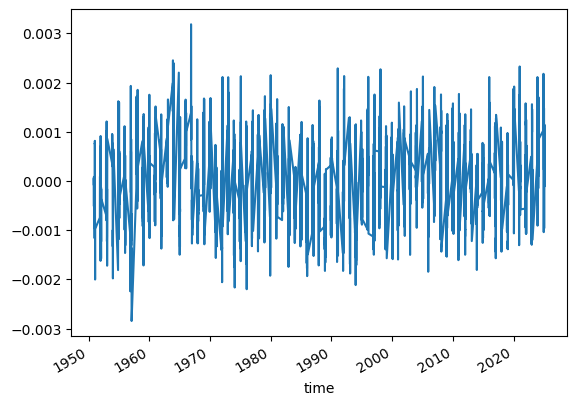

In [18]:
df_var_week3['q850_max'].plot()

In [19]:
# Name files appropriately:

df_var_week3.to_csv('q850_week3.csv')
df_var_week4.to_csv('q850_week4.csv')